In [ ]:
import torch

#requires_grad=True tells auto grad to track value

#radial coordinate
r = torch.tensor(30000.1, dtype=torch.float64, requires_grad=True)

# spherical coordinate
r_s = torch.tensor(0.00887, dtype=torch.float64)

# eqn
t = 2*r * (torch.sqrt(r/r_s) * torch.sqrt(1-r_s/r))

# pass to auto grad via backward pass to compute gradients
t.backward()

# where t = tau
print("t:", round(t.item(), 3))

t: 110344877.048


In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
import pandas as pd

url = ("https://raw.githubusercontent.com/rahulbhadani/Datasets/refs/heads/master/RAV4/2020-04-15-05-12-00_2T3Y1RFV8KC014025_CAN_Messages_5_Hz.csv")
file = pd.read_csv(url)

# steer angle is 2D feature
x = file[["steer_angle"]] 
y = file["yaw_rate"]

# 25% test rows, leaves 75% training 
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.25)

model = LinearRegression().fit(x_train, y_train)
r2 = r2_score(y_test, model.predict(x_test))

print("R^2:", round(r2,6))
print("w0 (intercept):", round(model.intercept_, 6))
print("w1 (slope) :", round(model.coef_[0],6))

R^2: 0.555705
w0 (intercept): -0.222632
w1 (slope) : 0.068765


w0 (intercept): -3820.145901
w1 (slope): 13583.531594
R^2 (test): 0.584303
sklearn w0: -3820.145901
sklearn w1: 13583.531594
sklearn R^2: 0.584303
predict BCR=1.0: [9763.38569296]
history lengths: 500 500 500
loss first -> last: 162743848.1048951 -> 60912416.18523339


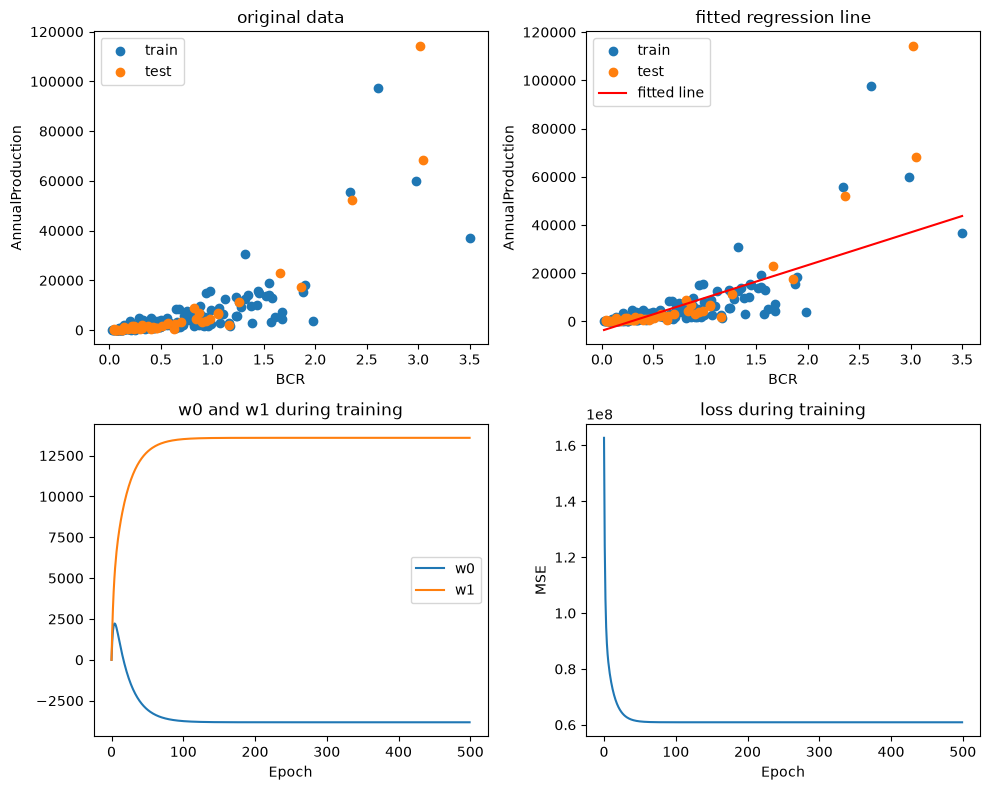

In [ ]:
import pandas as pd
from prettyjoey.model import LinearRegression
from sklearn.linear_model import LinearRegression as SkLinearRegression
from sklearn.model_selection import train_test_split

url = "https://raw.githubusercontent.com/rahulbhadani/Datasets/master/Hydropower.csv"
file = pd.read_csv(url)
x = file["BCR"]
y = file["AnnualProduction"]
# forcing random state allows us to see if data is reproducing correctly each time
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=20)
# 500 epochs = 600 epochs or >600
model = LinearRegression(learning_rate=0.1, epochs=500)
model.fit(x_train, y_train, x_test, y_test)

sk = SkLinearRegression().fit(x_train.to_frame(), y_train)

print("sklearn w0:", round(sk.intercept_, 6))
print("sklearn w1:", round(sk.coef_[0], 6))
print("sklearn R^2:", round(sk.score(x_test.to_frame(), y_test), 6))

# predict
print("predict BCR=1.0:", model.predict(1.0))
# past
print("history lengths:", len(model.loss_past), len(model.w0_past), len(model.w1_past))
print("loss first -> last:", model.loss_past[0], "->", model.loss_past[-1])
# plot
model.analysis_plot()